#전체적인 설명

0. 가중치에 대한 식을 먼저 계산. 감성분석은 kobert를 사용해 모델 생성, 학습 후 긍정, 부정, 대한 확률을 도출.
1. 현재 사용한 데이터는 kospi200 [ 2022.1.27 ~ 2024.12.30 ] 에 데이터를 기준으로 주가예측
2. 2022.1.27일 부터 시작한 이유는 lg energe solution 이라는 기업이 이때 상장을 하였기 때문에 지정
3. 처음에는 기업에 대한 정보를 company로 지정하여 동적으로 데이터를 옮기고 사용
4. 가중치는 감정분석결과[pos,neg],거래량,변동성, 임의로 만든 확률 계산식 [ 3개 중에 가장 높은 결과 도출한 식 사용 ]
5. 본래 가중치로 kospi200에 차지하는 비중을 넣어보았지만 값에 부정적인 영향을 줌. 이를 해결하기 위해 논문과 인터넷을 찾아본 결과 단기적인 주가 예측에는 부정적인 영향을 준다는 글을 확인. 배제
6. 그 후 sigmoid,minmax와 같은 식들로 정규화 및 전처리를 진행
7. x축은 date, y축은 target인 colsing value로 잡아서 진행
8. 결과를 기반으로 hybrid ensenble 진행. 쓴 모델은 LSTM, CNN, GRU
9. 논문에 있는 글을 참조하여 올려보았고, 전체적인 값은 우수하게 도출해냄. 논문과의 차별점은 기존 시장에 데이터만 사용한 것이 아니라 거래량, 변동성, 감정 계산식 같이 유의미한 데이터 사용, 그 외에도 hybrid ensenble을 사용하여 깊게 학습하였음. 자체적으로 최적화 값을 찾은 후, gpt에게 시계열 처리 값과 모델 구조 10개 숫자를 입력한 후 코드 생성 후 결과 도출.
그로 인해 좋은 결과 얻음.

결과1 : 가공하지 않은 순수 데이터로 예측

결과2 : klue를 통해 감성분석을 한 긍정,부정 데이터로 예측

결과3 ; 감성분석 확률을 pos - neg 같은 feature를 추가하여 유의미한 데이터 추가

결과4 : 하이퍼파라미터와 코스피 별 가중치 추가

최정결과 : 논문보다 월등히까지는 아니지만 높은 정보를 도출하였음

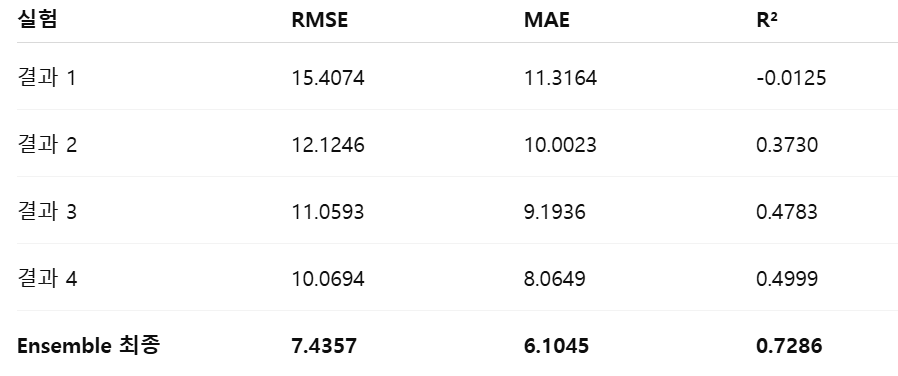

#google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#import

**warning : tensorflow import happened problem**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout, GRU
from keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from functools import reduce

#kospi200_data

**we have m,d date status is 1 27 we must change 01 27**

In [ ]:
companies = [
    "Hyundai", "Kbfg", "Kia", "Lgchem", "Lgensol", "Naver", "PoscoHoldings",
    "SamsungBiologics", "Samsung", "Skhynix"
]

kospi_path = '/content/drive/MyDrive/dataset/kospi200_cleaned_data.csv'

df_kospi = pd.read_csv(kospi_path)
df_kospi['y'] = df_kospi['y'].astype(str)
df_kospi['m'] = df_kospi['m'].astype(str).str.zfill(2)
df_kospi['d'] = df_kospi['d'].astype(str).str.zfill(2)
df_kospi['date'] = pd.to_datetime(df_kospi['y'] + df_kospi['m'] + df_kospi['d'],format="%Y%m%d")
df_kospi = df_kospi[['date', 'closing price','change']]
df_kospi = df_kospi.sort_values('date').reset_index(drop=True)
df_kospi['target'] = df_kospi['closing price'].shift(-1)
df_kospi.dropna(inplace=True)

df_kospi.head()

,date,closing price,change,target
0,2022-01-27,348.58,-3.39,357.98
1,2022-01-28,357.98,2.70,361.60
2,2022-02-03,361.60,1.01,366.34
3,2022-02-04,366.34,1.31,362.92
4,2022-02-07,362.92,-0.93,363.48


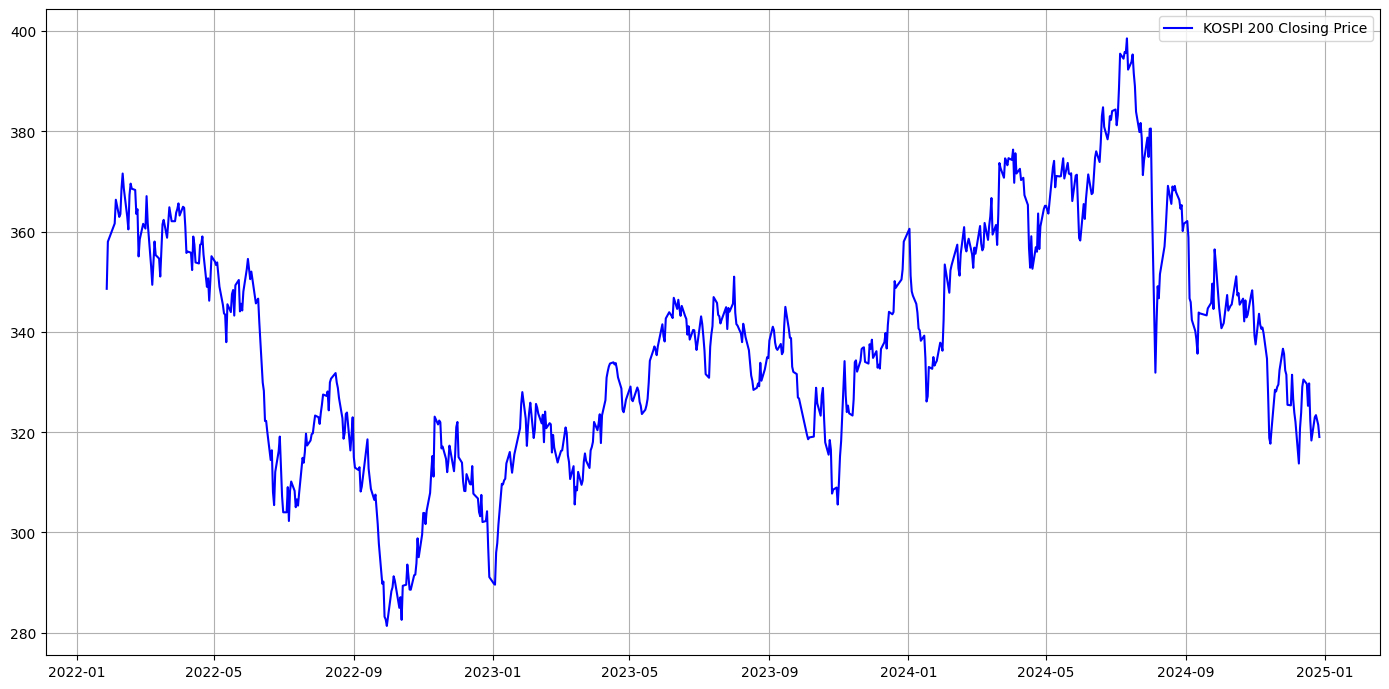

In [ ]:
plt.figure(figsize=(14, 7))
plt.plot(df_kospi['date'], df_kospi['closing price'], label='KOSPI 200 Closing Price', color='blue')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#append trading,change data

In [ ]:
import os

trading_path = "/content/drive/MyDrive/share_drive/박박박사/기업별_거래량_변동성"

In [ ]:
for company in companies:
  file_path = os.path.join(trading_path, f"df_{company}.csv")
  df_temp = pd.read_csv(file_path)
  df_sorted = df_temp.sort_values(by='날짜', ascending=True)
  df_sorted['날짜'] = pd.to_datetime(df_sorted['날짜'], format="%Y- %m- %d", errors='coerce')
  globals()[f'df_trading_{company}'] = df_sorted
  globals()[f'df_trading_{company}'].rename(columns={'날짜': 'date','거래량':'trading','변동 %':'change'}, inplace=True)

In [ ]:
df_trading_Hyundai.head()

,date,trading,change
823,2022-01-27,6.65M,-3.40%
822,2022-01-28,4.71M,6.17%
821,2022-02-03,5.08M,2.90%
820,2022-02-04,3.02M,0.40%
819,2022-02-06,NaN,0.00%


#data re manufacturing

In [ ]:
companies_2 = [
    "SamsungBiologics",
    "Naver",
    "Samsung",
    "Skhynix",
    "PoscoHoldings",
    "Lgensol",
    "Hyundai",
    "Kia",
    "Lgchem",
    "Kbfg"
]
new_col_names = {
    'A': '일자',
    'B': '부정',
    'C': '긍정',
    'E': '요일',
    'F': '공백'
}

folder_path = "/content/drive/MyDrive/share_drive/박박박사/작업중/점수합후 4로 나눔"

for company in companies_2:
    path = f"{folder_path}/{company}_aggregated_sentiment_holiday_sum_merged_result_AVG.csv"
    df = pd.read_csv(path)
    globals()[f"df_start_{company}"] = df
    df.rename(columns=new_col_names, inplace=True)
    globals()[f"df_start_{company}"] = df

In [ ]:
df_start_Hyundai.head()

,일자,부정,긍정,요일,공백
0,20220127,0.256409,0.743591,Thursday,0.0
1,20220128,0.452091,0.547909,Friday,0.0
2,20220131,0.170472,0.829528,MondayTuesdayWednesdayThursday,0.0
3,20220204,0.063104,0.186896,NaN,NaN
4,20220207,0.327487,0.672513,Monday,0.0


In [ ]:
df_start_Hyundai.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 729 entries, 0 to 728
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   일자      729 non-null    int64  
 1   부정      729 non-null    float64
 2   긍정      729 non-null    float64
 3   요일      675 non-null    object 
 4   공백      675 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 28.6+ KB


In [ ]:
for company in companies:
    df = globals()[f"df_start_{company}"]
    df['일자'] = pd.to_datetime(df['일자'].astype(str), format="%Y%m%d")
    df['감정'] = df.apply(lambda row: '부정' if row['부정'] > row['긍정'] else '긍정', axis=1)
    df['감정'] = df['감정'].map({'긍정': 1, '부정': -1})
    df.drop(columns=['공백','요일'], inplace=True)

    globals()[f"df_start_{company}"] = df
    globals()[f"df_start_{company}"].rename(columns={'일자': 'date','부정':'neg','긍정':'pos','감정':'emotion'}, inplace=True)

In [ ]:
df_start_Hyundai.head()

,date,neg,pos,emotion
0,2022-01-27,0.256409,0.743591,1
1,2022-01-28,0.452091,0.547909,1
2,2022-01-31,0.170472,0.829528,1
3,2022-02-04,0.063104,0.186896,1
4,2022-02-07,0.327487,0.672513,1


#Market capitalization ratio [ 값에 부정적인 영향을 주므로 보류 ]

In [ ]:
# capitalization_path = "/content/drive/MyDrive/share_drive/박박박사/시가총액/최종"

# companies = [
#     "SamsungBiologics",
#     "Naver",
#     "Samsung",
#     "Skhynix",
#     "PoscoHoldings",
#     "Lgensol",
#     "Hyundai",
#     "Kia",
#     "Lgchem",
#     "Kbfg"
# ]

In [ ]:
# for company in companies:
#     path = f"{capitalization_path}/{company}.csv"
#     df = pd.read_csv(path)
#     globals()[f"df_cap_{company}"] = df
#     globals()[f"df_cap_{company}"].rename(columns={'날짜': 'date','코스피비중': 'cospi_percent'}, inplace=True)
#     globals()[f'df_cap_{company}'].drop(columns=['코스피 시가총액','3개월 평균 시가총액'], inplace=True)

In [ ]:
# cospi_dataframes = {}

# cospi_data = {
#     'SamsungBiologics': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [2.56, 2.80, 3.13, 3.42, 2.95, 2.74, 2.57, 2.68, 2.94, 2.57, 2.90, 3.28]
#     },
#     'Naver': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [2.57, 2.06, 1.92, 1.70, 1.76, 1.64, 1.68, 1.77, 1.63, 1.35, 1.15, 1.42]
#     },
#     'Samsung': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [20.52, 18.10, 18.17, 20.24, 19.45, 20.80, 19.87, 22.46, 23.01, 22.25, 18.73, 15.62]
#     },
#     'Skhynix': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [4.25, 3.59, 3.54, 3.46, 3.36, 3.86, 4.19, 4.98, 5.86, 6.99, 5.64, 6.14]
#     },
#     'PoscoHoldings': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [1.21, 1.10, 1.09, 1.36, 1.49, 1.66, 2.32, 2.04, 1.83, 1.52, 1.27, 1.17]
#     },
#     'Lgensol': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [4.97, 4.60, 5.70, 6.93, 6.73, 6.66, 5.89, 5.18, 4.66, 3.96, 3.70, 4.31]
#     },
#     'Hyundai': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [1.85, 1.88, 2.12, 1.99, 1.97, 2.15, 1.94, 2.03, 2.47, 2.59, 2.22, 2.13]
#     },
#     'Kia': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [1.49, 1.59, 1.65, 1.49, 1.63, 1.74, 1.57, 1.79, 2.28, 2.27, 1.81, 1.79]
#     },
#     'Lgchem': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [1.87, 1.83, 2.27, 2.62, 2.61, 2.50, 1.97, 1.75, 1.57, 1.24, 0.97, 0.97]
#     },
#     'Kbfg': {
#         'date': pd.to_datetime(['2022-01-27', '2022-04-27', '2022-07-26', '2022-10-24', '2023-01-25', '2023-04-24', '2023-07-21', '2023-10-19', '2024-01-17', '2024-04-16', '2024-07-15', '2024-10-14']),
#         'cospi_percent': [1.21, 1.06, 1.04, 1.19, 1.08, 0.98, 1.05, 1.11, 1.35, 1.48, 1.45, 1.69]
#     }
# }

In [ ]:
# for company, data in cospi_data.items():
#     df = pd.DataFrame(data).sort_values('date')
#     globals()[f"df_cospi_{company}"] = df

# df_cospi_Hyundai.head()

#merge


In [ ]:
for company in companies:
    df_trading = globals()[f"df_trading_{company}"]
    df_start = globals()[f"df_start_{company}"]
    #df_cap = globals()[f"df_cap_{company}"]

    df_trading['date'] = pd.to_datetime(df_trading['date'])
    df_start['date'] = pd.to_datetime(df_start['date'])
    #df_cap['date'] = pd.to_datetime(df_cap['date'])


    df_merged = pd.merge(df_trading, df_start, on='date', how='inner')


    def convert_trading(val):
        if isinstance(val, str):
            val = val.strip()
            if val.endswith(('k', 'K')):
                return float(val[:-1]) * 1_000
            elif val.endswith('M'):
                return float(val[:-1]) * 1_000_000
            else:
                return int(val)
        return val

    df_merged['trading'] = df_merged['trading'].apply(convert_trading)
    df_merged['change'] = df_merged['change'].str.replace('%', '', regex=False).astype(float).round(3)

    #df_merged = df_merged.sort_values('date')

    # df_cap = df_cap.sort_values('date').reset_index(drop=True)
    # df_cap['start'] = df_cap['date']
    # df_cap['end'] = df_cap['date'].shift(-1) - pd.Timedelta(days=1)
    # df_cap.at[df_cap.index[-1], 'end'] = pd.Timestamp('2024-12-30')

    # def assign_cospi(row, cap_df):
    #     match = cap_df[(cap_df['start'] <= row['date']) & (row['date'] <= cap_df['end'])]
    #     return match['cospi_percent'].values[0] if not match.empty else np.nan

    df_merged['calculate'] = (df_merged['pos'] - df_merged['neg'])
    #df_merged['cospi_percent'] = df_merged.apply(lambda row: assign_cospi(row, df_cap), axis=1)

    globals()[f"df_merged_{company}"] = df_merged

In [ ]:
feature_frames = []

for company in companies:
    df = globals()[f"df_merged_{company}"]

    df_features = df[['date',
                           'neg',
                           'pos',
                           'emotion','trading','change'
                      ,'calculate'
                      #,'cospi_percent'
                      ]].copy()
    df_features.rename(columns={
        'neg': f'neg_{company}',
        'pos': f'pos_{company}',
        'emotion': f'emotion_{company}',
        'trading': f'trading_{company}',
        'change': f'change_{company}'
        ,'calculate':f'calculate_{company}'
        #,'cospi_percent':f'cospi_percent_{company}'
    }, inplace=True)

    feature_frames.append(df_features)

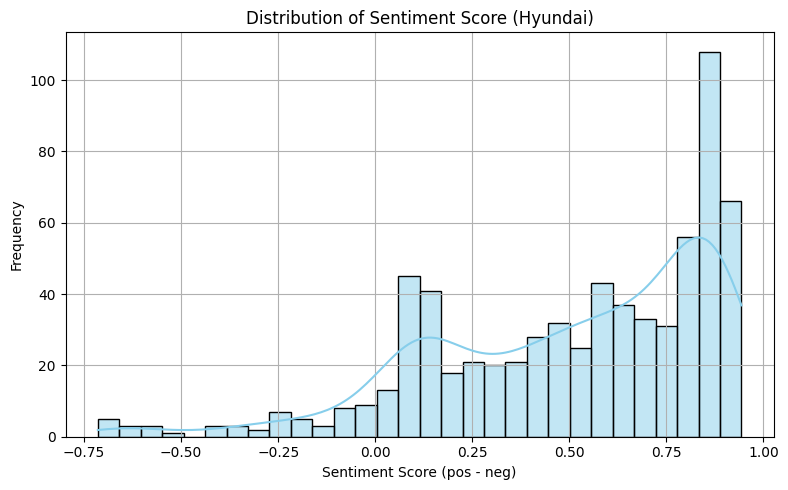

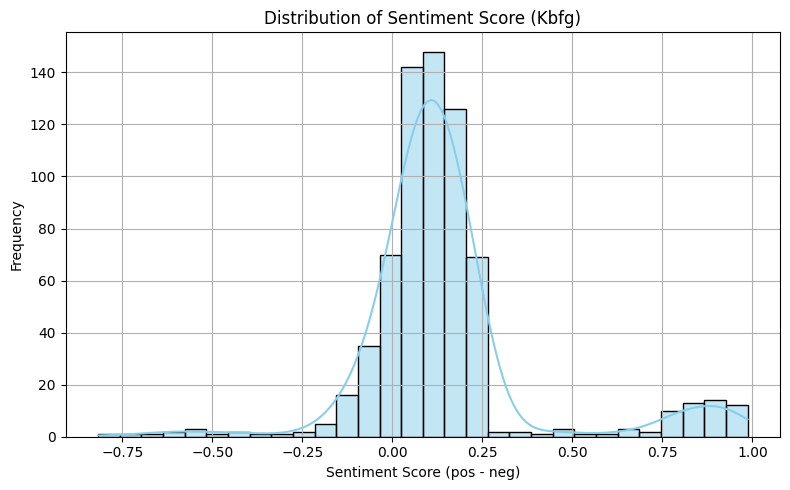

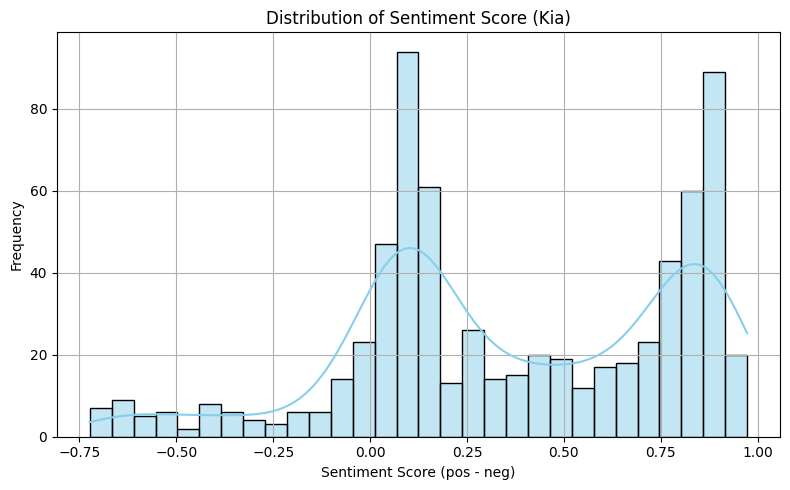

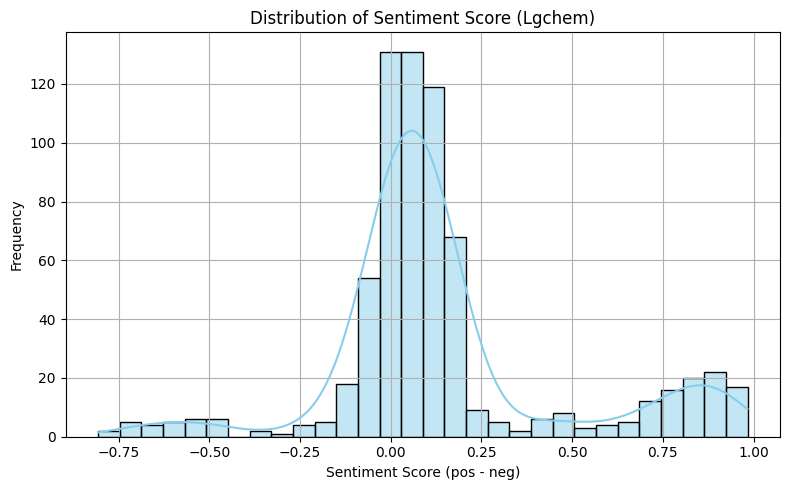

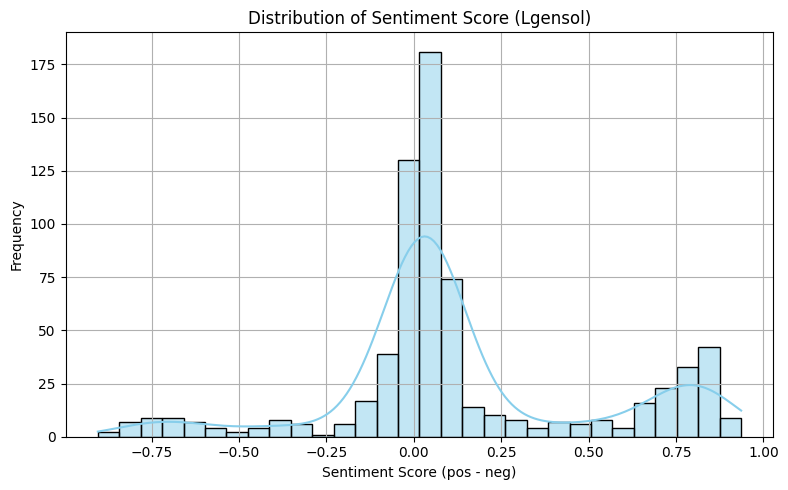

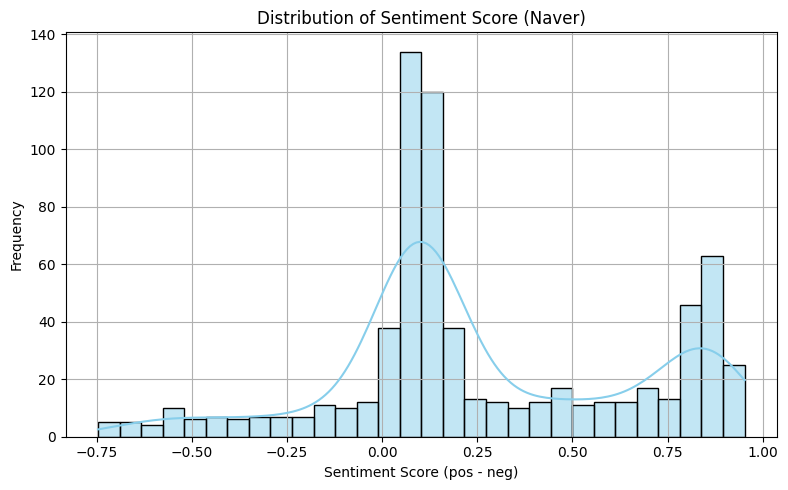

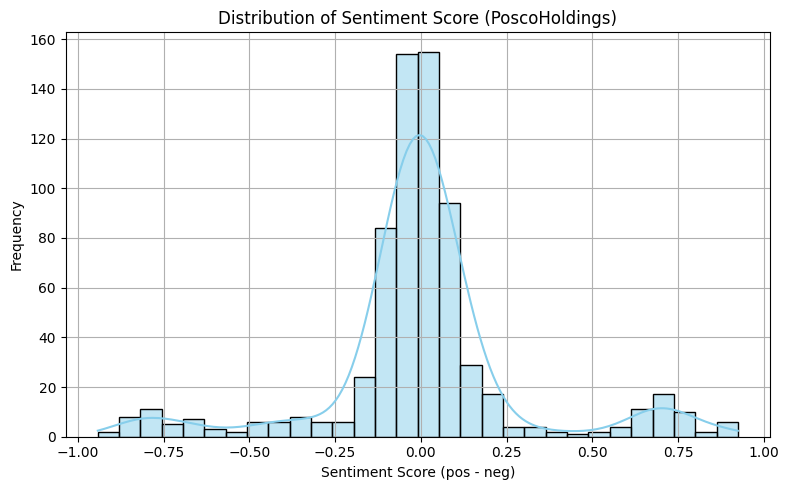

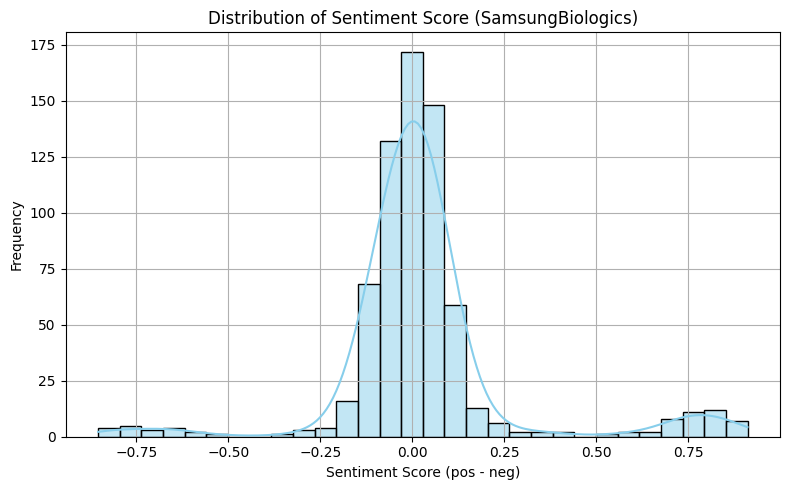

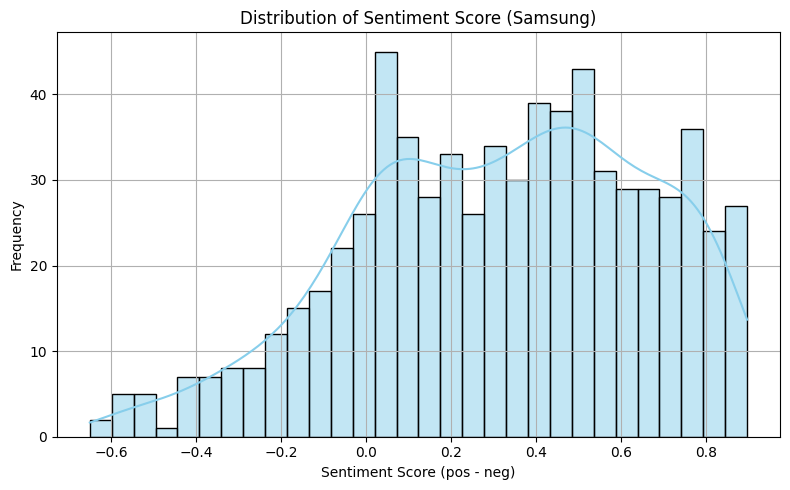

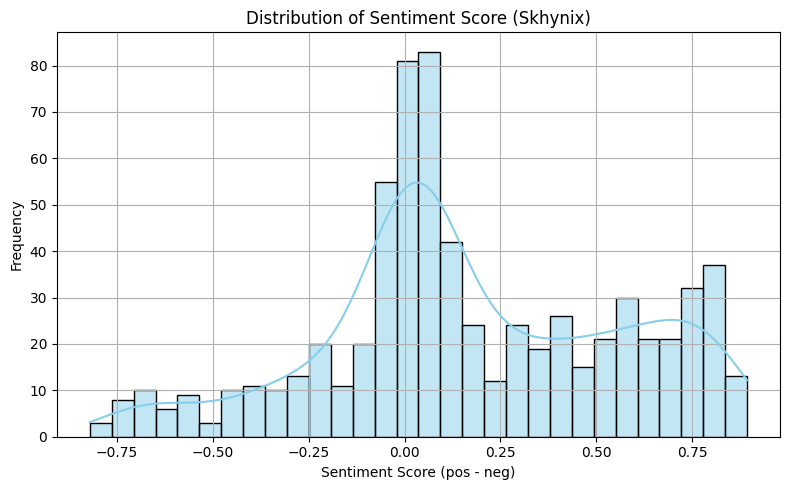

In [ ]:
df_merged_all = reduce(lambda left, right: pd.merge(left, right, on='date', how='inner'), feature_frames)

df_all = pd.merge(df_merged_all, df_kospi[['date', 'target']], left_on='date', right_on='date', how='inner')
df_all.sort_values('date', inplace=True)
df_all.reset_index(drop=True, inplace=True)

for company in companies:
    col_name = f'calculate_{company}'
    if col_name in df_all.columns:
        plt.figure(figsize=(8, 5))
        sns.histplot(df_all[col_name], kde=True, bins=30, color='skyblue')
        plt.title(f'Distribution of Sentiment Score ({company})')
        plt.xlabel('Sentiment Score (pos - neg)')
        plt.ylabel('Frequency')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

feature_cols = []
for company in companies:
    feature_cols.extend([
        f'neg_{company}',
        f'pos_{company}',
        f'emotion_{company}',
        f'trading_{company}',
        f'change_{company}'
        ,f'calculate_{company}'
        #,f'cospi_percent_{company}'
        ])
X = df_all[feature_cols].values
y = df_all['target'].values.reshape(-1, 1)

In [ ]:
df_merged_Hyundai.head()

,date,trading,change,neg,pos,emotion,calculate
0,2022-01-27,6650000.0,-3.40,0.256409,0.743591,1,0.487181
1,2022-01-28,4710000.0,6.17,0.452091,0.547909,1,0.095818
2,2022-02-04,3020000.0,0.40,0.063104,0.186896,1,0.123793
3,2022-02-07,4780000.0,-1.20,0.327487,0.672513,1,0.345026
4,2022-02-08,4020000.0,1.63,0.053130,0.946870,1,0.893740


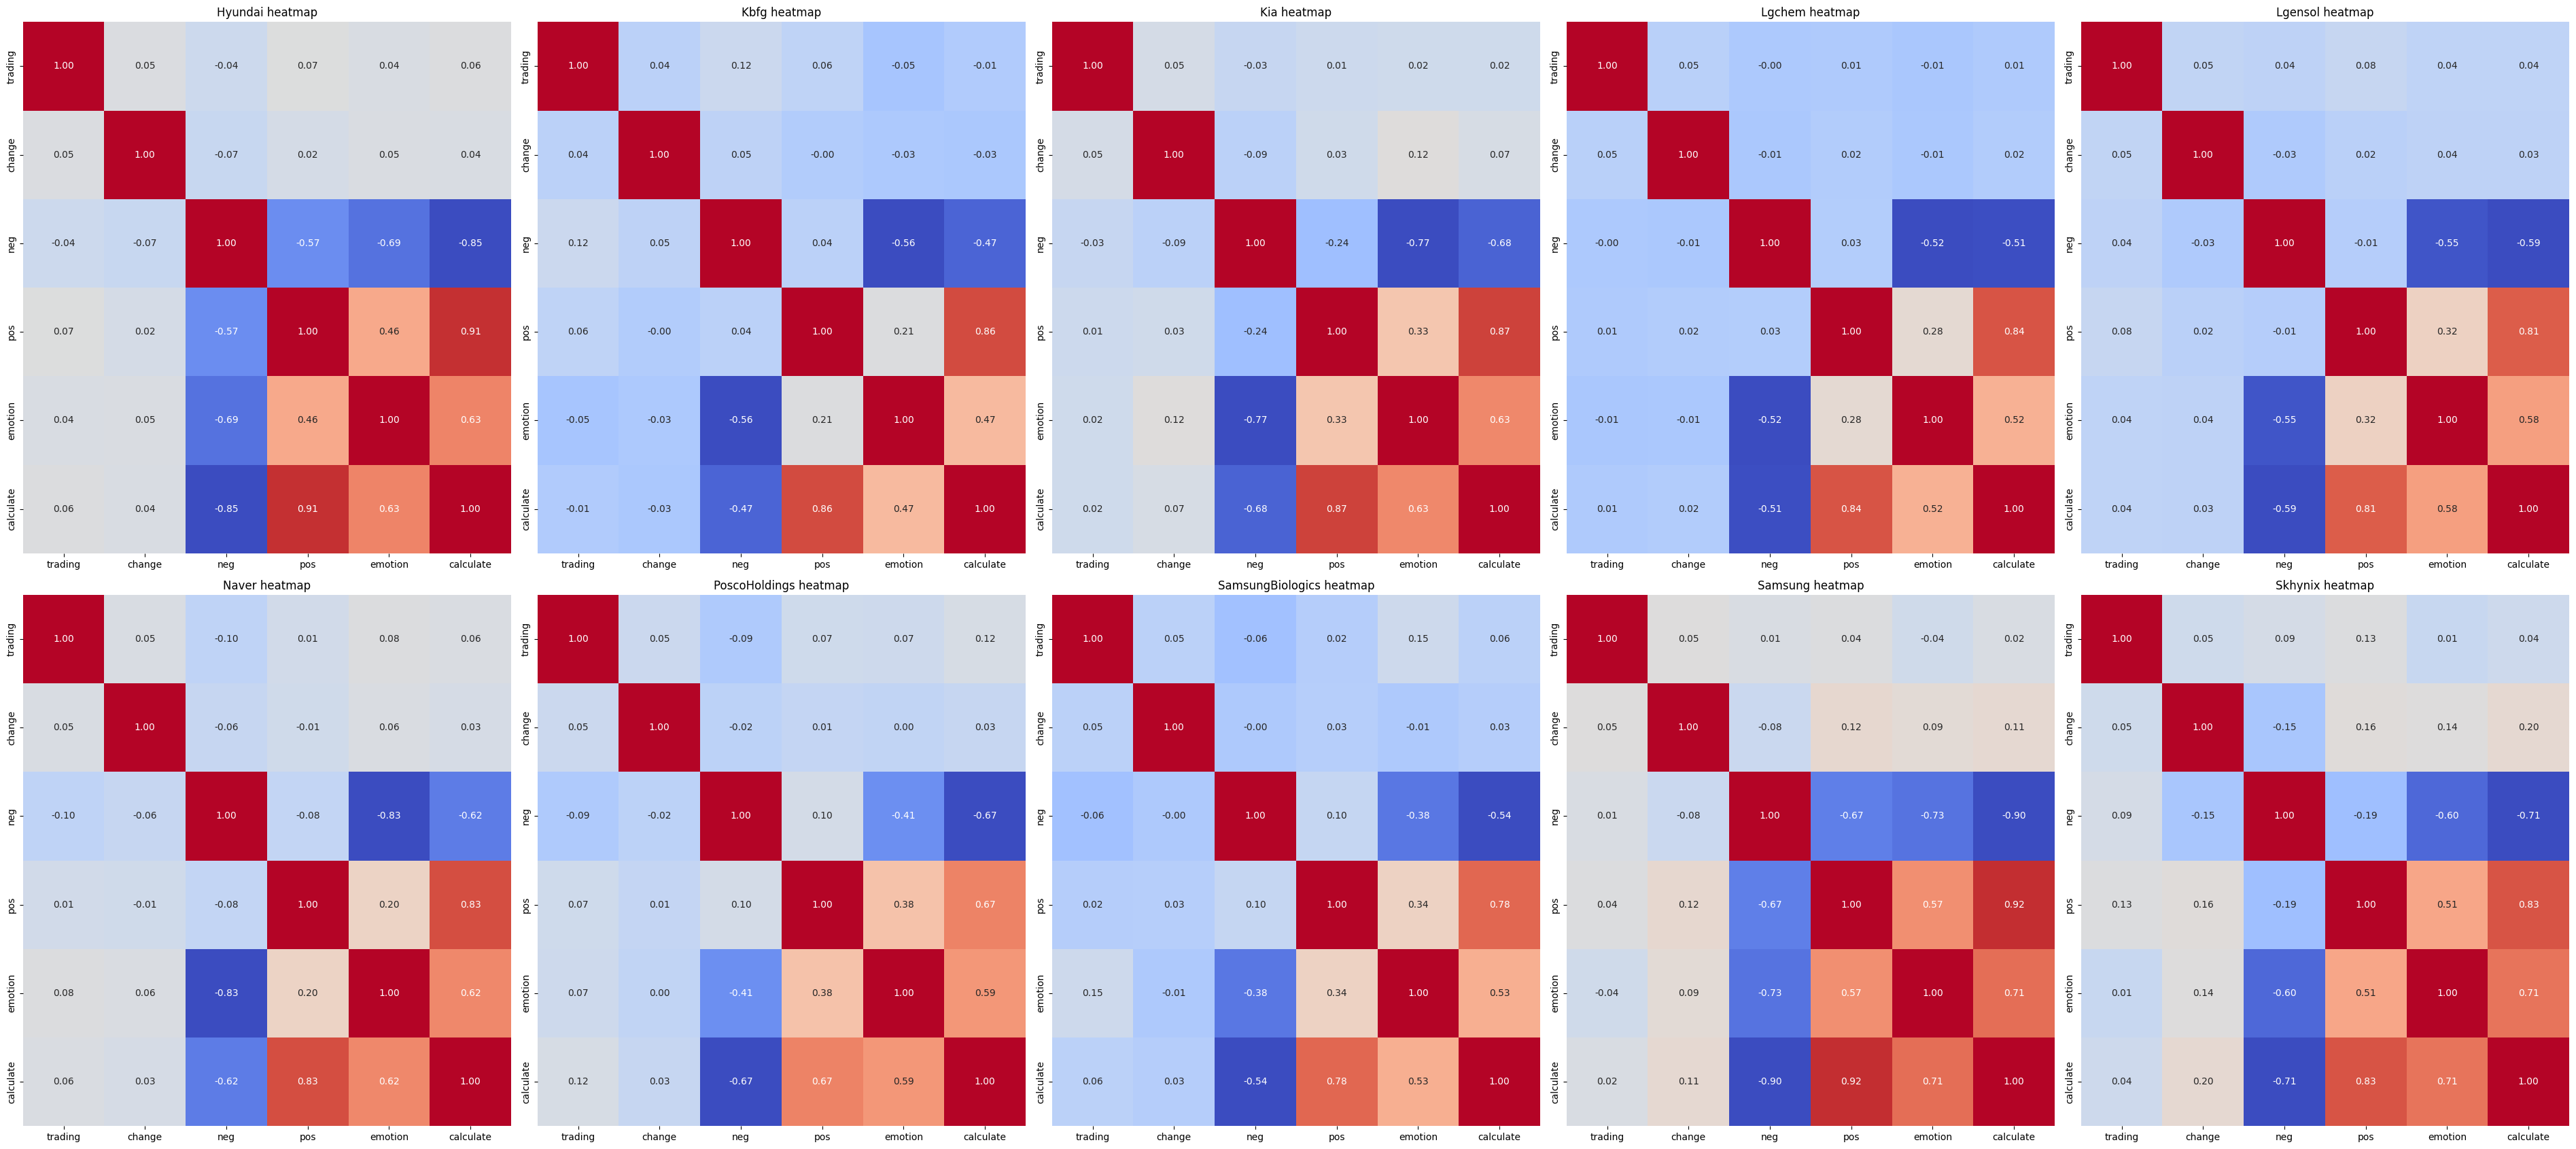

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(38, 17))
axes = axes.flatten()

for i, company in enumerate(companies):
    try:
        df = globals()[f"df_merged_{company}"]

        corr_matrix = df.drop('date', axis=1).corr()

        sns.heatmap(corr_matrix, ax=axes[i], annot=True, cmap='coolwarm', fmt=".2f", cbar=False)
        axes[i].set_title(f'{company} heatmap')
    except KeyError:
        axes[i].set_visible(False)

plt.tight_layout()
plt.show()


#scaling

In [ ]:
# scaler_X = StandardScaler()
# scaler_y = StandardScaler()

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

def Sequences(X, y, time_steps):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:i+time_steps])
        ys.append(y[i+time_steps])
    return np.array(Xs), np.array(ys)

In [ ]:
time_steps = 21
X_seq, y_seq = Sequences(X_scaled, y_scaled, time_steps)

Total samples: 669
Train samples: 474
Validation samples: 102
Test samples: 93


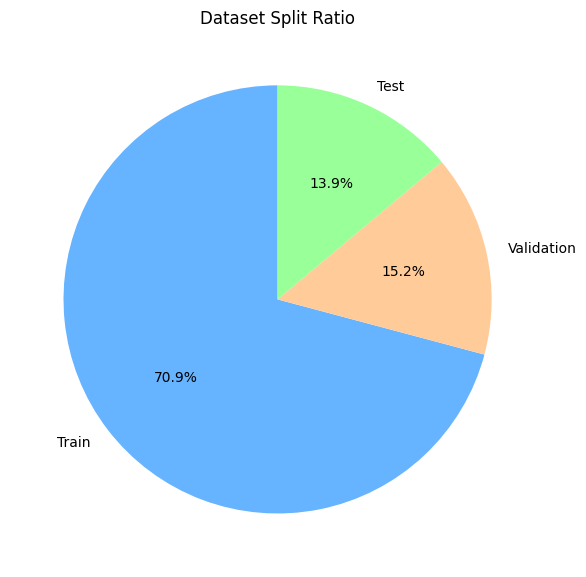

In [ ]:
train_ratio = 0.71
val_ratio = 0.151

total_len = len(X_seq)
train_split_index = int(total_len * train_ratio)
val_split_index = int(total_len * (train_ratio + val_ratio))

X_train, y_train = X_seq[:train_split_index], y_seq[:train_split_index]
X_val, y_val = X_seq[train_split_index:val_split_index], y_seq[train_split_index:val_split_index]
X_test, y_test = X_seq[val_split_index:], y_seq[val_split_index:]

print(f"Total samples: {total_len}")
print(f"Train samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples: {len(X_test)}")

splits = [len(X_train), len(X_val), len(X_test)]
labels = ['Train', 'Validation', 'Test']

plt.figure(figsize=(6,6))
plt.pie(splits, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ffcc99','#99ff99'])
plt.title("Dataset Split Ratio")
plt.tight_layout()
plt.show()

**Dropout : prevent Overfitting**

**Dense : Fully Connected Layer**

In [ ]:
model = Sequential([
    LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.25),
    LSTM(50,return_sequences=True),
    Dropout(0.19),
    LSTM(25,return_sequences=False),
    Dropout(0.1),
    Dense(1)
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


#learing

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 0.0412 - val_loss: 0.1337
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0200 - val_loss: 0.0771
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0125 - val_loss: 0.1184
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0095 - val_loss: 0.0876
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0101 - val_loss: 0.1093
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0068 - val_loss: 0.0943
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0071 - val_loss: 0.1153
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0084 - val_loss: 0.0836
Epoch 9/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0092 - val_loss: 0.0856
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 187ms/step


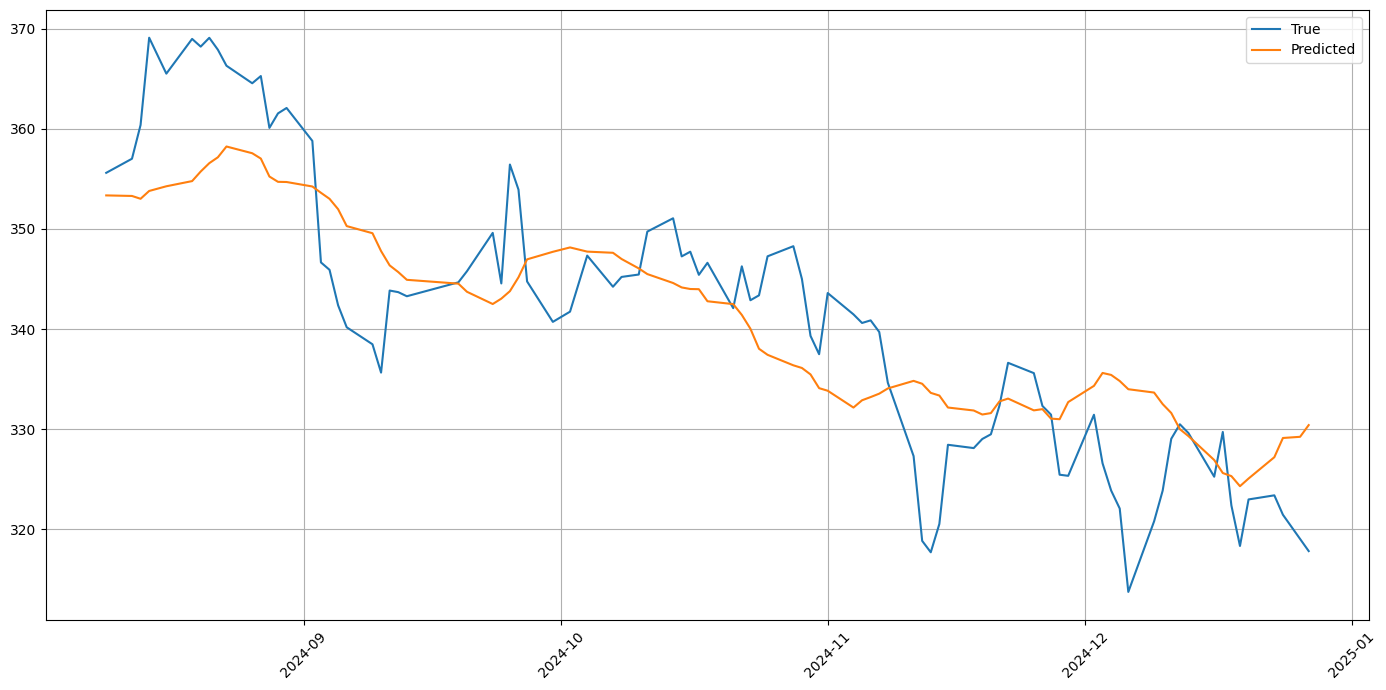

 RMSE: 7.7143
 MAE: 6.3124
 R2: 0.7079


In [ ]:
model.compile(optimizer='adam', loss='mse')
es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    callbacks=[es],
    verbose=1
)

y_pred = model.predict(X_test)
y_pred_inverse = scaler_y.inverse_transform(y_pred)
y_true_inverse = scaler_y.inverse_transform(y_test)

dates_test = df_all['date'].values[val_split_index + time_steps:]
dates_test_dt = pd.to_datetime(dates_test.astype(str))

plt.figure(figsize=(14, 7))
plt.plot(dates_test_dt, y_true_inverse, label='True')
plt.plot(dates_test_dt, y_pred_inverse, label='Predicted')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rmse = np.sqrt(mean_squared_error(y_true_inverse, y_pred_inverse))
mae = mean_absolute_error(y_true_inverse, y_pred_inverse)
r2 = r2_score(y_true_inverse, y_pred_inverse)
print(f" RMSE: {rmse:.4f}")
print(f" MAE: {mae:.4f}")
print(f" R2: {r2:.4f}")

#ensemble1


kci : https://www.kci.go.kr/kciportal/ci/sereArticleSearch/ciSereArtiView.kci?sereArticleSearchBean.artiId=ART003104513

arxiv : https://arxiv.org/abs/2410.20253

In [ ]:
import random
import tensorflow as tf
from keras.layers import Conv1D, MaxPooling1D, Flatten,GlobalAveragePooling1D
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

**num_models를 1 ~ 10까지 돌려본 결과 3과 10에서 지표가 괜찮게 나왔는데 10을 지정**

In [ ]:
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

results = []

ensemble_preds_lstm = []
ensemble_preds_gru = []
ensemble_preds_cnn_lstm = []

num_models = 9

**cnn모델에서 flatten말고 glovalaveragepool 를사용. overfitting방지를 방지하기 위해였지만 결과값이 좋지 않아 배재. 그 외에 각 모델별로 2층이랑 3층을 번갈아가면 결과 확인**

In [ ]:
for seed in range(num_models):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    model_lstm = Sequential([
        LSTM(100, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
        Dropout(0.25),
        LSTM(50, return_sequences=True),
        Dropout(0.19),
        LSTM(25, return_sequences=False),
        Dropout(0.1),
        Dense(1)
    ])
    model_lstm.compile(optimizer='adam', loss='mse')
    es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    model_lstm.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_val, y_val), callbacks=[es], verbose=0)
    pred = model_lstm.predict(X_test, verbose=0)
    ensemble_preds_lstm.append(pred)

for seed in range(num_models):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    model_gru = Sequential([
        GRU(100, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
        Dropout(0.25),
        GRU(50, return_sequences=True),
        Dropout(0.19),
        GRU(25, return_sequences=False),
        Dropout(0.1),
        Dense(1)
    ])
    model_gru.compile(optimizer='adam', loss='mse')
    es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    model_gru.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_val, y_val), callbacks=[es], verbose=0)
    pred = model_gru.predict(X_test, verbose=0)
    ensemble_preds_gru.append(pred)

for seed in range(num_models):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    model_cnn_lstm = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
        MaxPooling1D(pool_size=2),
        LSTM(50, return_sequences=True),
        Dropout(0.19),
        Flatten(),
        #GlobalAveragePooling1D(),
        Dense(1)
    ])
    model_cnn_lstm.compile(optimizer='adam', loss='mse')
    es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    model_cnn_lstm.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_val, y_val), callbacks=[es], verbose=0)
    pred = model_cnn_lstm.predict(X_test, verbose=0)
    ensemble_preds_cnn_lstm.append(pred)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#predict

**본래 일반 평균과 가중치 평균을 비교 해보니 대부분 지표가 일반 평균이 좋았기 때문에 지정**

**Threshold tunning으로 FP줄이는 방법사용**

In [ ]:
y_pred_avg_lstm = np.mean(ensemble_preds_lstm, axis=0)
y_pred_avg_gru = np.mean(ensemble_preds_gru, axis=0)
y_pred_avg_cnn_lstm = np.mean(ensemble_preds_cnn_lstm, axis=0)
y_pred_total_avg = (y_pred_avg_lstm + y_pred_avg_gru + y_pred_avg_cnn_lstm) / 3

y_pred_inverse = scaler_y.inverse_transform(y_pred_total_avg)
y_true_inverse = scaler_y.inverse_transform(y_test)

y_prev_close = df_all['target'].values[val_split_index + time_steps - 1: val_split_index + time_steps - 1 + len(y_true_inverse)]

y_true_direction = (y_true_inverse.flatten() > y_prev_close).astype(int)
y_pred_direction = (y_pred_inverse.flatten() > y_prev_close).astype(int)

dates_test_start = len(df_all) - len(y_test)
dates_test = df_all['date'].values[dates_test_start:]
dates_test_dt = pd.to_datetime(dates_test)

In [ ]:
print(np.bincount(y_true_direction))

[51 42]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

**가중치 평균은 예측자체를 못하므로 보류**

In [ ]:
# w_lstm, w_cnn, w_gru = 0.43, 0.30, 0.27

# y_pred_avg_lstm = np.mean(ensemble_preds_lstm, axis=0)
# y_pred_avg_gru = np.mean(ensemble_preds_gru, axis=0)
# y_pred_avg_cnn_lstm = np.mean(ensemble_preds_cnn_lstm, axis=0)

# y_pred_total_avg = (
#     w_lstm * y_pred_avg_lstm +
#     w_cnn * y_pred_avg_cnn_lstm +
#     w_gru * y_pred_avg_gru
# )

# y_pred_inverse = scaler_y.inverse_transform(y_pred_total_avg)
# y_true_inverse = scaler_y.inverse_transform(y_test)

# dates_test_start = len(df_all) - len(y_test)
# dates_test = df_all['date'].values[dates_test_start:]
# dates_test_dt = pd.to_datetime(dates_test)

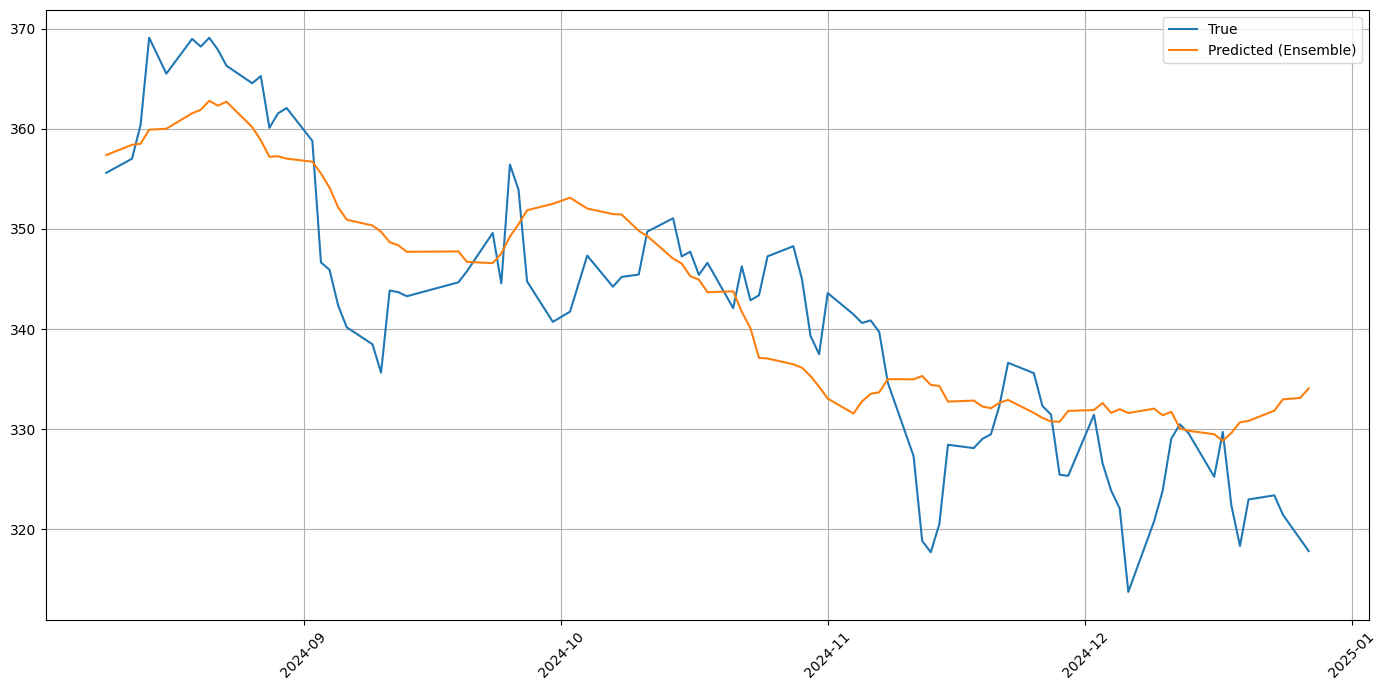

 RMSE: 7.4450
 MAE: 6.1273
 R2: 0.7279
 MAPE: 0.0182
 F1 Score: 0.5934


In [ ]:
plt.figure(figsize=(14, 7))
plt.plot(dates_test_dt, y_true_inverse, label='True')
plt.plot(dates_test_dt, y_pred_inverse, label='Predicted (Ensemble)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rmse = np.sqrt(mean_squared_error(y_true_inverse, y_pred_inverse))
mae = mean_absolute_error(y_true_inverse, y_pred_inverse)
r2 = r2_score(y_true_inverse, y_pred_inverse)
mape = mean_absolute_percentage_error(y_true_inverse, y_pred_inverse)
f1 = f1_score(y_true_direction, y_pred_direction)

print(f" RMSE: {rmse:.4f}")
print(f" MAE: {mae:.4f}")
print(f" R2: {r2:.4f}")
print(f" MAPE: {mape:.4f}")
print(f" F1 Score: {f1:.4f}")

/tmp/ipython-input-1719745289.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(metrics.keys()), y=list(metrics.values()), palette="Set2")


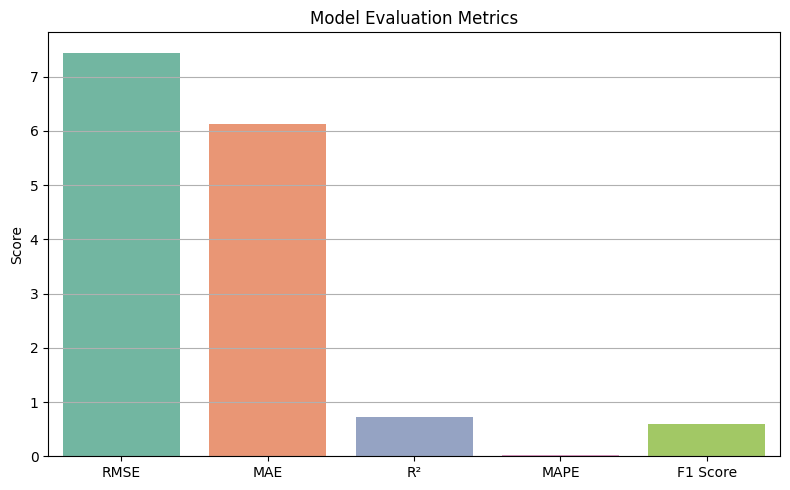

In [ ]:
metrics = {
    "RMSE": rmse,
    "MAE": mae,
    "R²": r2,
    "MAPE": mape,
    "F1 Score": f1
}

plt.figure(figsize=(8,5))
sns.barplot(x=list(metrics.keys()), y=list(metrics.values()), palette="Set2")
plt.title("Model Evaluation Metrics")
plt.ylabel("Score")
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

<Figure size 500x500 with 0 Axes>

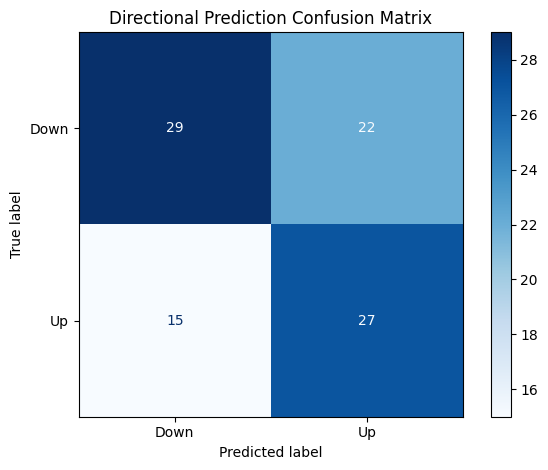

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true_direction, y_pred_direction)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Down", "Up"])

plt.figure(figsize=(5,5))
disp.plot(cmap='Blues', values_format='d')
plt.title("Directional Prediction Confusion Matrix")
plt.grid(False)
plt.tight_layout()
plt.show()

#optimizer target value

**해당 식은 직접 값을 찾은 후 해당 값 부근을 여러개 지정하여 최상의 값을 찾음. 그 후 위에 있는 ensemble 데이터에 삽입**

In [ ]:
# import random
# import tensorflow as tf

# tf.random.set_seed(42)
# np.random.seed(42)
# random.seed(42)

# results = []

In [ ]:
# time_steps_options = list(range(18, 22))
# train_ratio_options = [0.69, 0.70, 0.71]
# val_ratio_options = [0.149, 0.150, 0.151]


# lstm_units_options = [
#     (64, 32, 16),
#     (96, 48, 24),
#     (128, 64, 32),
#     (80, 40, 20),
#     (100, 50, 25)
# ]

# dropout_options = []
# for d1 in [0.2, 0.25, 0.3]:
#     for d2 in [0.19, 0.2, 0.21]:
#         d3 = 0.1
#         dropout_options.append((d1, d2, d3))


# all_combinations = []
# for ts in time_steps_options:
#     for tr in train_ratio_options:
#         for vr in val_ratio_options:
#             for lu in lstm_units_options:
#                 for do in dropout_options:
#                     all_combinations.append({
#                         'time_steps': ts,
#                         'train_ratio': tr,
#                         'val_ratio': vr,
#                         'lstm_units': lu,
#                         'dropout': do
#                     })

# if len(all_combinations) > 30:
#     selected_combinations = random.sample(all_combinations, 30)
# else:
#     selected_combinations = all_combinations

# print(f"\n--- Running {len(selected_combinations)} Experiments ---")

# for i, params in enumerate(selected_combinations):
#     print(f"\nExperiment {i+1}/{len(selected_combinations)}: {params}")

#     rmse_list, mae_list, r2_list = [], [], []

#     for run in range(5):  # 5번 반복
#         time_steps = params['time_steps']
#         train_ratio = params['train_ratio']
#         val_ratio = params['val_ratio']
#         lstm_units = params['lstm_units']
#         dropout = params['dropout']

#         X_seq, y_seq = Sequences(X_scaled, y_scaled, time_steps)
#         total_len = len(X_seq)

#         if train_ratio + val_ratio >= 1.0:
#             continue

#         train_split_index = int(total_len * train_ratio)
#         val_split_index = int(total_len * (train_ratio + val_ratio))
#         if train_split_index >= val_split_index or val_split_index >= total_len:
#             continue

#         X_train, y_train = X_seq[:train_split_index], y_seq[:train_split_index]
#         X_val, y_val = X_seq[train_split_index:val_split_index], y_seq[train_split_index:val_split_index]
#         X_test, y_test = X_seq[val_split_index:], y_seq[val_split_index:]

#         model = Sequential([
#             LSTM(lstm_units[0], return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
#             Dropout(dropout[0]),
#             LSTM(lstm_units[1], return_sequences=True),
#             Dropout(dropout[1]),
#             LSTM(lstm_units[2], return_sequences=False),
#             Dropout(dropout[2]),
#             Dense(1)
#         ])

#         model.compile(optimizer='adam', loss='mse')
#         es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

#         model.fit(
#             X_train, y_train,
#             epochs=50,
#             batch_size=16,
#             validation_data=(X_val, y_val),
#             callbacks=[es],
#             verbose=0
#         )

#         y_pred = model.predict(X_test, verbose=0)
#         y_pred_inverse = scaler_y.inverse_transform(y_pred)
#         y_true_inverse = scaler_y.inverse_transform(y_test)

#         rmse_list.append(np.sqrt(mean_squared_error(y_true_inverse, y_pred_inverse)))
#         mae_list.append(mean_absolute_error(y_true_inverse, y_pred_inverse))
#         r2_list.append(r2_score(y_true_inverse, y_pred_inverse))


#     if rmse_list:
#         results.append({
#             'params': params,
#             'rmse': np.mean(rmse_list),
#             'mae': np.mean(mae_list),
#             'r2': np.mean(r2_list)
#         })

# # 내림차순 정렬
# results.sort(key=lambda x: (x['rmse'], x['mae'], -x['r2']))

# print("\n--- Top 5 Best Results (Averaged over 5 runs) ---")
# for i, res in enumerate(results[:5]):
#     print(f"\nRank {i+1}:")
#     print(f"  Parameters: {res['params']}")
#     print(f"  RMSE: {res['rmse']:.4f}")
#     print(f"  MAE: {res['mae']:.4f}")
#     print(f"  R2: {res['r2']:.4f}")

In [ ]:
# feature_frames = []
# for company in companies:
#     df = globals()[f"df_merged_{company}"]
#     df_features = df[['date', 'neg', 'pos', 'emotion', 'trading', 'change', 'calculate']].copy()
#     df_features.rename(columns={
#         'neg': f'neg_{company}', 'pos': f'pos_{company}', 'emotion': f'emotion_{company}',
#         'trading': f'trading_{company}', 'change': f'change_{company}', 'calculate': f'calculate_{company}'
#     }, inplace=True)
#     feature_frames.append(df_features)

# df_merged_all = reduce(lambda left, right: pd.merge(left, right, on='date', how='inner'), feature_frames)
# df_all = pd.merge(df_merged_all, df_kospi[['date', 'target']], on='date', how='inner')
# df_all.sort_values('date', inplace=True)
# df_all.reset_index(drop=True, inplace=True)

# feature_cols = []
# for company in companies:
#     feature_cols.extend([
#         f'neg_{company}', f'pos_{company}', f'emotion_{company}',
#         f'trading_{company}', f'change_{company}', f'calculate_{company}'
#     ])
# X = df_all[feature_cols].values
# y = df_all['target'].values.reshape(-1, 1)

# scaler_X = MinMaxScaler()
# scaler_y = MinMaxScaler()
# X_scaled = scaler_X.fit_transform(X)
# y_scaled = scaler_y.fit_transform(y)

# def Sequences(X, y, time_steps):
#     Xs, ys = [], []
#     for i in range(len(X) - time_steps):
#         Xs.append(X[i:i + time_steps])
#         ys.append(y[i + time_steps])
#     return np.array(Xs), np.array(ys)

# time_steps_options = list(range(18, 22))
# train_ratio_options = [0.69, 0.70, 0.71]
# val_ratio_options = [0.149, 0.150, 0.151]
# units_options = [
#     (64, 32, 16),
#     (96, 48, 24),
#     (128, 64, 32),
#     (80, 40, 20),
#     (100, 50, 25)
# ]
# dropout_options = [(d1, d2, 0.1) for d1 in [0.2, 0.25, 0.3] for d2 in [0.19, 0.2, 0.21]]

# all_gru_combinations = []
# for ts in time_steps_options:
#     for tr in train_ratio_options:
#         for vr in val_ratio_options:
#             for u in units_options:
#                 for d in dropout_options:
#                     all_gru_combinations.append({'time_steps': ts, 'train_ratio': tr, 'val_ratio': vr, 'units': u, 'dropout': d})
# selected_gru_combinations = random.sample(all_gru_combinations, 30) if len(all_gru_combinations) > 30 else all_gru_combinations

# all_cnn_lstm_combinations = []
# cnn_filters_options = [32, 64, 96]
# cnn_lstm_units_options = [64, 48, 32]
# for ts in time_steps_options:
#     for tr in train_ratio_options:
#         for vr in val_ratio_options:
#             for filters in cnn_filters_options:
#                 for units in cnn_lstm_units_options:
#                     for d in dropout_options:
#                          all_cnn_lstm_combinations.append({'time_steps': ts, 'train_ratio': tr, 'val_ratio': vr, 'filters': filters, 'lstm_units': units, 'dropout': d})
# selected_cnn_lstm_combinations = random.sample(all_cnn_lstm_combinations, 30) if len(all_cnn_lstm_combinations) > 30 else all_cnn_lstm_combinations


# gru_results = []
# print("--- GRU 모델 하이퍼파라미터 탐색 시작 ---")
# for i, params in enumerate(selected_gru_combinations):
#     print(f"GRU Experiment {i+1}/{len(selected_gru_combinations)}: {params}")
#     rmse_list, mae_list, r2_list = [], [], []
#     time_steps = params['time_steps']
#     train_ratio = params['train_ratio']
#     val_ratio = params['val_ratio']
#     units = params['units']
#     dropout = params['dropout']
#     try:
#         X_seq, y_seq = Sequences(X_scaled, y_scaled, time_steps)
#         total_len = len(X_seq)
#         if train_ratio + val_ratio >= 1.0 or int(total_len * train_ratio) >= int(total_len * (train_ratio + val_ratio)) or int(total_len * (train_ratio + val_ratio)) >= total_len:
#             continue
#         train_split_index = int(total_len * train_ratio)
#         val_split_index = int(total_len * (train_ratio + val_ratio))
#         X_train, y_train = X_seq[:train_split_index], y_seq[:train_split_index]
#         X_val, y_val = X_seq[train_split_index:val_split_index], y_seq[train_split_index:val_split_index]
#         X_test, y_test = X_seq[val_split_index:], y_seq[val_split_index:]

#         for run in range(5):
#             tf.random.set_seed(42 + run)
#             np.random.seed(42 + run)
#             random.seed(42 + run)
#             model = Sequential([
#                 GRU(units[0], return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
#                 Dropout(dropout[0]),
#                 GRU(units[1], return_sequences=True),
#                 Dropout(dropout[1]),
#                 GRU(units[2], return_sequences=False),
#                 Dropout(dropout[2]),
#                 Dense(1)
#             ])
#             model.compile(optimizer='adam', loss='mse')
#             es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
#             model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_val, y_val), callbacks=[es], verbose=0)
#             y_pred = model.predict(X_test, verbose=0)
#             y_pred_inverse = scaler_y.inverse_transform(y_pred)
#             y_true_inverse = scaler_y.inverse_transform(y_test)
#             rmse_list.append(np.sqrt(mean_squared_error(y_true_inverse, y_pred_inverse)))
#             mae_list.append(mean_absolute_error(y_true_inverse, y_pred_inverse))
#             r2_list.append(r2_score(y_true_inverse, y_pred_inverse))

#         if rmse_list:
#             gru_results.append({
#                 'params': params,
#                 'rmse': np.mean(rmse_list),
#                 'mae': np.mean(mae_list),
#                 'r2': np.mean(r2_list)
#             })
#     except Exception as e:
#         print(f"Error with GRU combination {params}: {e}")
#         continue

# cnn_lstm_results = []
# print("\n--- CNN-LSTM 모델 하이퍼파라미터 탐색 시작 ---")
# for i, params in enumerate(selected_cnn_lstm_combinations):
#     print(f"CNN-LSTM Experiment {i+1}/{len(selected_cnn_lstm_combinations)}: {params}")
#     rmse_list, mae_list, r2_list = [], [], []
#     time_steps = params['time_steps']
#     train_ratio = params['train_ratio']
#     val_ratio = params['val_ratio']
#     filters = params['filters']
#     lstm_units = params['lstm_units']
#     dropout = params['dropout']
#     try:
#         X_seq, y_seq = Sequences(X_scaled, y_scaled, time_steps)
#         total_len = len(X_seq)
#         if train_ratio + val_ratio >= 1.0 or int(total_len * train_ratio) >= int(total_len * (train_ratio + val_ratio)) or int(total_len * (train_ratio + val_ratio)) >= total_len:
#             continue
#         train_split_index = int(total_len * train_ratio)
#         val_split_index = int(total_len * (train_ratio + val_ratio))
#         X_train, y_train = X_seq[:train_split_index], y_seq[:train_split_index]
#         X_val, y_val = X_seq[train_split_index:val_split_index], y_seq[train_split_index:val_split_index]
#         X_test, y_test = X_seq[val_split_index:], y_seq[val_split_index:]

#         for run in range(5):
#             tf.random.set_seed(42 + run)
#             np.random.seed(42 + run)
#             random.seed(42 + run)
#             model = Sequential([
#                 Conv1D(filters=filters, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
#                 MaxPooling1D(pool_size=2),
#                 LSTM(lstm_units, return_sequences=False),
#                 Dropout(dropout[1]),
#                 Dense(1)
#             ])
#             model.compile(optimizer='adam', loss='mse')
#             es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
#             model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_val, y_val), callbacks=[es], verbose=0)
#             y_pred = model.predict(X_test, verbose=0)
#             y_pred_inverse = scaler_y.inverse_transform(y_pred)
#             y_true_inverse = scaler_y.inverse_transform(y_test)
#             rmse_list.append(np.sqrt(mean_squared_error(y_true_inverse, y_pred_inverse)))
#             mae_list.append(mean_absolute_error(y_true_inverse, y_pred_inverse))
#             r2_list.append(r2_score(y_true_inverse, y_pred_inverse))

#         if rmse_list:
#             cnn_lstm_results.append({
#                 'params': params,
#                 'rmse': np.mean(rmse_list),
#                 'mae': np.mean(mae_list),
#                 'r2': np.mean(r2_list)
#             })
#     except Exception as e:
#         print(f"Error with CNN-LSTM combination {params}: {e}")
#         continue

# gru_results.sort(key=lambda x: (x['rmse'], x['mae'], -x['r2']))
# cnn_lstm_results.sort(key=lambda x: (x['rmse'], x['mae'], -x['r2']))

# print("\n--- GRU 모델 Top 5 결과 (5회 평균) ---")
# for i, res in enumerate(gru_results[:5]):
#     print(f"순위 {i+1}:")
#     print(f"  파라미터: {res['params']}")
#     print(f"  RMSE: {res['rmse']:.4f}")
#     print(f"  MAE: {res['mae']:.4f}")
#     print(f"  R2: {res['r2']:.4f}")

# print("\n--- CNN-LSTM 모델 Top 5 결과 (5회 평균) ---")
# for i, res in enumerate(cnn_lstm_results[:5]):
#     print(f"순위 {i+1}:")
#     print(f"  파라미터: {res['params']}")
#     print(f"  RMSE: {res['rmse']:.4f}")
#     print(f"  MAE: {res['mae']:.4f}")
#     print(f"  R2: {res['r2']:.4f}")